# MPD-cRDDME on the Fokker–Planck equation: harmonic well, periodic box

We test `DriftMpdRdmeSolver` against the
Fokker–Planck equation
$$\partial_t\rho = \nabla\!\cdot D\,[\nabla\rho + \rho\,\nabla\phi],$$
with a time-dependent dragged harmonic potential
$$\phi(\mathbf x,t)=\tfrac{k}{2}\sum_i\big(x_i - c\sin\omega t\big)^2 .$$
The exact solution is a Gaussian of fixed width $1/\sqrt{k}$ whose center follows the drive with
attenuation and phase lag:
$$\rho(\mathbf x,t)=\Big(\tfrac{k}{2\pi}\Big)^{3/2}\!\exp\!\Big[-\tfrac{k}{2}\sum_i (x_i-\mu)^2\Big],\quad
\mu=\frac{Dk}{\sqrt{(Dk)^2+\omega^2}}\,c\,\sin(\omega t-\delta),\quad \tan\delta=\frac{\omega}{Dk}.$$

Domain: periodic cube $[-256,256]^3$ (box units), $N=L/h$ voxels per side.

**Test 1: spatial convergence ($\omega=0$).** Static well at the box center. Fix $k$, sweep $h$
(i.e. $N$). The WPE hop satisfies detailed balance, so the discrete stationary distribution is
exactly $\rho_i\propto e^{-\phi_i}$; we measure how this discrete equilibrium approaches the
continuum Gaussian as $h\to0$.

**Test 2: dynamic response ($\omega>0$).** Moving well driven by a per-step field update; we track
the cloud center $\mu(t)$ and check the analytic amplitude attenuation and phase lag.



In [3]:
import os, sys, tempfile
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '/lm/build_v1')
import lm
from jLM.RDME import Sim as RDMESim
from jLM import Solvers
assert hasattr(lm, 'DriftMpdRdmeSolver')

# ---- physics (box units; 1 unit = UNIT meters) --------------------------------
L      = 256.0        # box edge (box units)
UNIT   = 1e-8         # meters per box unit (10 nm) -- only sets absolute scale
D      = 1e-12        # diffusion constant [m^2/s]
K      = 0.01         # spring constant [1/unit^2]  -> width sigma = 1/sqrt(K) = 10 units
SIGMA  = 1.0 / np.sqrt(K)
# relaxation rate Dk is resolution independent: Dk = D * K / UNIT^2
DK     = D * K / UNIT**2
C_STAB = 0.10         # hop probability q0 = C_STAB (< diffusion CFL 1/6, << WPE 0.98)
PPS    = lm.getCompiledLatticeMaxOccupancy()

print(f'sigma = {SIGMA:.1f} box units;  Dk = {DK:.1f} /s  (relaxation time {1/DK*1e3:.2f} ms);  PPS = {PPS}')

sigma = 10.0 box units;  Dk = 100.0 /s  (relaxation time 10.00 ms);  PPS = 16


## Test 1: spatial convergence, static well ($\omega=0$)


In [4]:
def build_static_field(N):
    """phi_i = (K/2) * sum_a ((idx_a - N/2) * h)^2, in box units, C-flattened float32."""
    h = L / N
    ax = ((np.arange(N) - N / 2.0) * h).astype(np.float64)   # position - center, per axis
    # phi = (K/2)(ax_x^2 + ax_y^2 + ax_z^2) via broadcasting (memory-lean for large N)
    phi = 0.5 * K * (ax[:, None, None]**2 + ax[None, :, None]**2 + ax[None, None, :]**2)
    return np.ascontiguousarray(phi.ravel(order='C'), dtype=np.float32), h


def seed_gaussian(sim, P, N, n_part, rng):
    """Place n_part particles drawn from N(center, sigma_voxels) independently per axis."""
    h = L / N
    sigv = SIGMA / h                       # std in voxels
    c = N / 2.0
    pos = np.round(c + sigv * rng.standard_normal((n_part, 3))).astype(np.int64)
    pos = np.clip(pos, 0, N - 1)
    vox, cnt = np.unique(pos, axis=0, return_counts=True)
    cnt = np.minimum(cnt, PPS)              # never exceed the 16 particle/voxel cap
    for (x, y, z), n in zip(vox, cnt):
        sim.placeNumber(P, int(x), int(y), int(z), int(n))
    return sigv


def run_static(N, workdir, run_steps=3000, n_frames=30, occ_frac=0.25, max_part=300_000, seed=0):
    h = L / N
    sigv = SIGMA / h
    dt = C_STAB * (h * UNIT)**2 / D
    n_part = int(np.clip(occ_frac * PPS * (2 * np.pi)**1.5 * sigv**3, 200, max_part))
    rng = np.random.default_rng(seed)

    fname = os.path.join(workdir, f'fpA_N{N}.lm')
    sim = RDMESim(name=f'fpA_N{N}', filename=fname, dimensions=[N, N, N],
                  latticeSpacing=h * UNIT, regionName='cyt', latticeType='Byte', dt=dt)
    P = sim.species('P'); sim.diffusionConst('D', D)
    sim.transitionRate(None, None, None, sim.diffusionZero)             # periodic single region
    sim.transitionRate(P, sim.region('cyt'), sim.region('cyt'), sim.dc.D)
    seed_gaussian(sim, P, N, n_part, rng)
    sim.simulationTime = run_steps * dt
    sim.latticeWriteInterval = max(1, run_steps // n_frames)
    sim.speciesWriteInterval = sim.latticeWriteInterval

    psi0, _ = build_static_field(N)
    sim.finalize()
    solver = lm.DriftMpdRdmeSolver()
    solver.setPotentialBasis(psi0, np.zeros_like(psi0))
    solver.setSpeciesCoupling(0, 1.0, 0.0)
    f = sim.run(solver=solver, cudaDevices=[0])

    # time-average the per-voxel density over the second half (static -> valid)
    grp = f.h5['Simulations/0000001/Lattice']; keys = sorted(grp.keys())[len(grp) // 2:]
    # 1-D marginal along solver-x (= HDF5 frame axis 0): sum over the other axes
    marg = np.zeros(N, dtype=np.float64)
    for k in keys:
        marg += (grp[k][...] == P.idx).sum(axis=3).sum(axis=(1, 2))
    marg /= len(keys)
    return dict(N=N, h=h, sigv=sigv, n_part=n_part, marg=marg,
                max_occ=float(marg.max() / max(1, n_part) * n_part))

In [5]:
N_SWEEP = [32, 64, 128, 256, 512]
resA = {}
with tempfile.TemporaryDirectory() as wd:
    for N in N_SWEEP:
        print(f'--- Part A  N = {N:5d}  (h = {L/N:.3f} units, sigma = {SIGMA/(L/N):.2f} vox) ...', flush=True)
        try:
            resA[N] = run_static(N, wd)
            print(f'    done: n_part={resA[N]["n_part"]}', flush=True)
        except Exception as exc:
            print(f'    FAILED: {type(exc).__name__}: {exc}', flush=True)

--- Part A  N =    32  (h = 8.000 units, sigma = 1.25 vox) ...
2026-05-22 18:01:20) Info: Using 224 processor(s) and 1 CUDA device(s) per process.
2026-05-22 18:01:20) Info: Assigning 1.00 processor(s) and 1.00 CUDA device(s) per replicate.
2026-05-22 18:01:20) Info: Data output thread running.
2026-05-22 18:01:20) Info: MPDRDME: Rng seed: top word 4169992050, bottom word 1
2026-05-22 18:01:20) Info: Running mpd rdme simulation with 1 species, 0 reactions, 1 site types for 1.920000e+00 s with tau 6.400000e-04. Writing species at 6.952725e-310 and lattice at 5.371318e-310 intervals
2026-05-22 18:01:20) Info: Time is 0.06400000000000
2026-05-22 18:01:20) Info: Lattice write time is 0.06400000000000, in steps is 100
2026-05-22 18:01:20) Info: Next lattice write time is 200
2026-05-22 18:01:20) Info: Time is 0.12800000000000
2026-05-22 18:01:20) Info: Lattice write time is 0.12800000000000, in steps is 200
2026-05-22 18:01:20) Info: Next lattice write time is 300
2026-05-22 18:01:20) Info:

In [ ]:
# Replicate runner: 3 independent seeds, full per-frame 3-D occupancy saved
# as chunked+gzipped HDF5 on /raid (symlinked from ./replicates).
# Each replicate is ~500 MB on disk; raw uint8 would be ~4.6 GB. Skips any
# replicate whose .h5 already exists, so this cell is safely re-runnable.
import h5py, time
from pathlib import Path

REPL_DIR = Path('replicates')           # -> /raid/racda/mpd-crddme-replicates
REPL_DIR.mkdir(exist_ok=True)
N_REPLICATES = 3

def run_static_to_h5(N, workdir, seed, run_steps=3000, n_frames=30, occ_frac=0.25, max_part=300_000):
    """Same run as run_static, but returns the (frames, times, n_part) for a single N."""
    h = L / N
    sigv = SIGMA / h
    dt = C_STAB * (h * UNIT)**2 / D
    n_part = int(np.clip(occ_frac * PPS * (2 * np.pi)**1.5 * sigv**3, 200, max_part))
    rng = np.random.default_rng(seed)

    fname = os.path.join(workdir, f'fpA_s{seed}_N{N}.lm')
    sim = RDMESim(name=f'fpA_s{seed}_N{N}', filename=fname, dimensions=[N, N, N],
                  latticeSpacing=h * UNIT, regionName='cyt', latticeType='Byte', dt=dt)
    P = sim.species('P'); sim.diffusionConst('D', D)
    sim.transitionRate(None, None, None, sim.diffusionZero)
    sim.transitionRate(P, sim.region('cyt'), sim.region('cyt'), sim.dc.D)
    seed_gaussian(sim, P, N, n_part, rng)
    sim.simulationTime = run_steps * dt
    sim.latticeWriteInterval = max(1, run_steps // n_frames)
    sim.speciesWriteInterval = sim.latticeWriteInterval

    psi0, _ = build_static_field(N)
    sim.finalize()
    solver = lm.DriftMpdRdmeSolver()
    solver.setPotentialBasis(psi0, np.zeros_like(psi0))
    solver.setSpeciesCoupling(0, 1.0, 0.0)
    f = sim.run(solver=solver, cudaDevices=[0])
    grp = f.h5['Simulations/0000001/Lattice']
    keys = sorted(grp.keys())
    times = f.h5['Simulations/0000001/LatticeTimes'][...]
    # frames: uint8 per-voxel count of species P (max PPS=16)
    frames = np.empty((len(keys), N, N, N), dtype=np.uint8)
    for fi, k in enumerate(keys):
        frames[fi] = (grp[k][...] == P.idx).sum(axis=3).astype(np.uint8)
    return frames, np.asarray(times[:len(keys)], dtype=np.float64), n_part

for seed in range(N_REPLICATES):
    out_path = REPL_DIR / f'static_seed{seed:04d}.h5'
    if out_path.exists():
        print(f'[seed {seed}] exists ({out_path.stat().st_size / 2**20:.1f} MB), skipping.', flush=True)
        continue
    print(f'=== Replicate seed = {seed} ===', flush=True)
    t_total = time.time()
    with tempfile.TemporaryDirectory() as wd, h5py.File(out_path, 'w') as fout:
        fout.attrs.update(dict(seed=seed, L=L, K=K, D=D, UNIT=UNIT, C_STAB=C_STAB,
                               PPS=int(PPS), N_SWEEP=np.array(N_SWEEP, dtype=np.int32)))
        for N in N_SWEEP:
            t0 = time.time()
            print(f'  N = {N:5d} ...', end=' ', flush=True)
            try:
                frames, times, n_part = run_static_to_h5(N, wd, seed=seed)
            except Exception as exc:
                print(f'FAILED: {type(exc).__name__}: {exc}', flush=True)
                continue
            grp = fout.create_group(f'N{N}')
            grp.attrs['n_part'] = n_part
            grp.attrs['h'] = L / N
            # chunk one frame per chunk so per-frame reads are fast
            grp.create_dataset('frames', data=frames, chunks=(1, N, N, N),
                               compression='gzip', compression_opts=4, shuffle=True)
            grp.create_dataset('times',  data=times)
            print(f'done in {time.time()-t0:.1f}s (n_part={n_part}, frames={frames.shape})', flush=True)
    print(f'  -> {out_path}  ({out_path.stat().st_size / 2**20:.1f} MB)   '
          f'total {time.time()-t_total:.1f}s', flush=True)

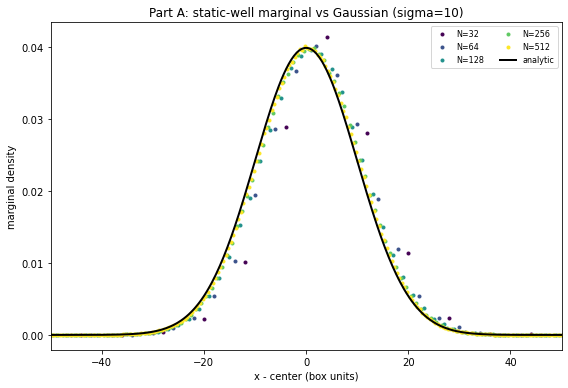

  N |  h     | sigma_vox | sigma_fit | L2 err
----+--------+-----------+-----------+---------
  32| 8.000 |     1.25  |    9.986  | 1.37e-01
  64| 4.000 |     2.50  |   10.090  | 4.96e-02
 128| 2.000 |     5.00  |   10.028  | 1.81e-02
 256| 1.000 |    10.00  |   10.013  | 6.79e-03
 512| 0.500 |    20.00  |   10.001  | 2.27e-03


In [6]:
def analytic_marginal(N):
    h = L / N
    x = (np.arange(N) + 0.5 - N / 2.0) * h        # box-unit offset from center
    g = np.exp(-x**2 / (2 * SIGMA**2)); return g / g.sum()

def fit_sigma(marg, h):
    p = marg / marg.sum(); x = np.arange(len(marg))
    m = (x * p).sum(); var = (p * (x - m)**2).sum()
    return np.sqrt(var) * h                       # back to box units

# Plot 1: marginal density vs analytic Gaussian, per N
fig, ax = plt.subplots(figsize=(8, 5.5))
Ns = [N for N in N_SWEEP if N in resA]
cmap = plt.get_cmap('viridis')
for i, N in enumerate(Ns):
    h = L / N; xb = (np.arange(N) + 0.5 - N / 2.0) * h
    p = resA[N]['marg'] / resA[N]['marg'].sum()
    ax.plot(xb, p / h, 'o', ms=3, color=cmap(i / max(1, len(Ns) - 1)), label=f'N={N}')
xf = np.linspace(-50, 50, 400)
ax.plot(xf, np.exp(-xf**2 / (2 * SIGMA**2)) / (SIGMA * np.sqrt(2 * np.pi)), 'k-', lw=2, label='analytic')
ax.set_xlim(-50, 50); ax.set_xlabel('x - center (box units)'); ax.set_ylabel('marginal density')
ax.set_title(f'Part A: static-well marginal vs Gaussian (sigma={SIGMA:.0f})'); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

print('  N |  h     | sigma_vox | sigma_fit | L2 err')
print('----+--------+-----------+-----------+---------')
for N in Ns:
    h = L / N; p = resA[N]['marg'] / resA[N]['marg'].sum()
    err = np.sqrt(np.sum((p - analytic_marginal(N))**2))
    print(f'{N:4d}| {h:.3f} |  {SIGMA/h:7.2f}  |  {fit_sigma(resA[N]["marg"], h):7.3f}  | {err:.2e}')

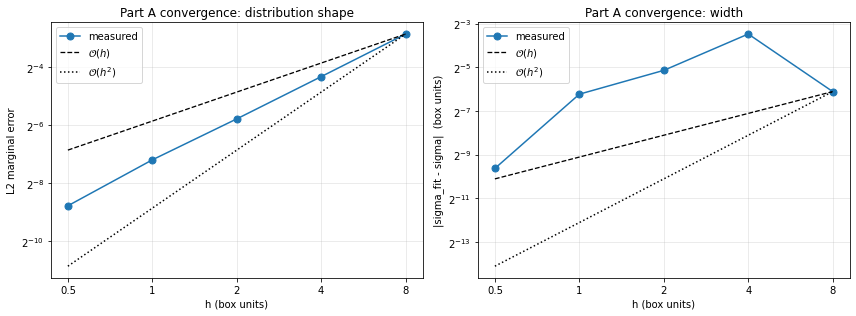

In [7]:
# Plot 2: convergence vs h, bracketed by labeled O(h) and O(h^2) guide lines (base-2 x-axis).
from matplotlib.ticker import FuncFormatter, NullFormatter
hs, errs, dsig = [], [], []
for N in Ns:
    h = L / N; p = resA[N]['marg'] / resA[N]['marg'].sum()
    hs.append(h)
    errs.append(np.sqrt(np.sum((p - analytic_marginal(N))**2)))
    dsig.append(abs(fit_sigma(resA[N]['marg'], h) - SIGMA))
hs, errs, dsig = map(np.array, (hs, errs, dsig))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, y, lab in ((a1, errs, 'L2 marginal error'), (a2, dsig, '|sigma_fit - sigma|  (box units)')):
    good = y > 0
    hh, yy = hs[good], y[good]
    ax.plot(hh, yy, 'o-', ms=7, color='C0', label='measured')
    # anchor both reference slopes at the coarsest point (largest h) so they bracket the data
    ia = int(np.argmax(hh)); h0, y0 = hh[ia], yy[ia]
    hl = np.array([hh.min(), hh.max()])
    ax.plot(hl, y0 * (hl / h0)**1, 'k--', lw=1.3, label=r'$\mathcal{O}(h)$')
    ax.plot(hl, y0 * (hl / h0)**2, 'k:',  lw=1.5, label=r'$\mathcal{O}(h^2)$')
    ax.set_xscale('log', base=2); ax.set_yscale('log', base=2)
    ax.set_xticks(hs)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('h (box units)'); ax.set_ylabel(lab)
    ax.grid(True, which='both', alpha=0.3); ax.legend()
a1.set_title('Part A convergence: distribution shape'); a2.set_title('Part A convergence: width')
plt.tight_layout(); plt.show()

[WM1] LaTeX binary not found; using matplotlib mathtext fallback.
  N |  h    | n_part |   abs L2 (1-D) |  shot mean   |   shot SD
----+-------+--------+----------------+--------------+-------------
  32| 8.000 |    200 |    1.371e-01    |  6.222e-02  |  2.70e-02
  64| 4.000 |    984 |    4.958e-02    |  3.003e-02  |  8.04e-03
 128| 2.000 |   7874 |    1.807e-02    |  1.095e-02  |  1.95e-03
 256| 1.000 |  62998 |    6.791e-03    |  3.928e-03  |  4.80e-04
 512| 0.500 | 300000 |    2.266e-03    |  1.813e-03  |  1.54e-04

absolute 1-D L2 convergence order ~ 1.47
  -> figures/wm1_l2_convergence.{pdf,png}


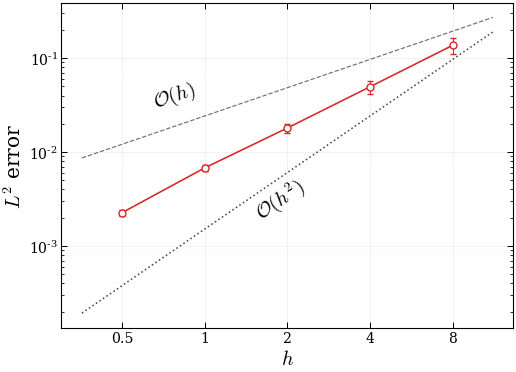

In [ ]:
# WM1: 1-D L2 convergence of the WPE-equilibrated marginal vs. the analytic
# Gaussian, as h -> 0. Plots the ABSOLUTE 1-D L2 error
#   L2(h) = || p(h) - a(h) ||_2
# where p is the time-averaged simulated x-marginal and a is the discrete
# analytic Gaussian on the same fine grid.
#
# Error bars are the THEORETICAL 1-SD Poisson shot-noise prediction:
#   E[||p-a||^2] = (1 - sum a^2) / n_part
#   SD[||p-a||]  = sqrt(2 sum a^2 / n_part^2) / (2 E[||p-a||])  (delta method)
# i.e. how much L2 would fluctuate across hypothetical replicates of the
# same n_part Monte Carlo simulation. A second dotted curve overlays the
# theoretical Poisson shot-noise mean -- at the current n_part the data
# falls right on top of it, confirming that what WM1 measures is the
# sampling floor, not the WPE quadrature error (which scales O(h^2.5)
# absolute, far below the floor; see WM5 for the WM prediction).
#
# O(h) and O(h^2) guide lines bracket the measurement as before.
# Saves figures/wm1_l2_convergence.{pdf,png}.
from matplotlib.ticker import FuncFormatter, NullFormatter
from pathlib import Path
import subprocess

FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

# Probe for LaTeX once -- fall back to mathtext if absent.
try:
    subprocess.run(['latex', '--version'], capture_output=True, check=True, timeout=5)
    USE_LATEX = True
except Exception:
    USE_LATEX = False
    print('[WM1] LaTeX binary not found; using matplotlib mathtext fallback.')

rc_pub = {
    'font.family':         'serif',
    'font.size':           14,
    'axes.labelsize':      16,
    'axes.titlesize':      15,
    'xtick.labelsize':     14,
    'ytick.labelsize':     14,
    'legend.fontsize':     14,
    'lines.linewidth':     1.6,
    'lines.markersize':    7,
    'axes.linewidth':      1.1,
    'xtick.direction':     'in',  'ytick.direction':     'in',
    'xtick.top':           True,  'ytick.right':         True,
    'xtick.minor.visible': True,  'ytick.minor.visible': True,
    'xtick.major.size':    6.0,   'ytick.major.size':    6.0,
    'xtick.minor.size':    3.0,   'ytick.minor.size':    3.0,
    'xtick.major.width':   1.0,   'ytick.major.width':   1.0,
    'xtick.minor.width':   0.8,   'ytick.minor.width':   0.8,
    'savefig.bbox':        'tight',
    'savefig.pad_inches':  0.05,
}
if USE_LATEX:
    rc_pub.update({'text.usetex': True, 'font.serif': ['Computer Modern Roman']})
else:
    rc_pub.update({'mathtext.fontset': 'cm'})

print('  N |  h    | n_part |   abs L2 (1-D) |  shot mean   |   shot SD')
print('----+-------+--------+----------------+--------------+-------------')
h_arr, rel1_arr, rel3_arr, shot_mean_arr, shot_sd_arr = [], [], [], [], []
for N in Ns:
    h = L / N
    p = resA[N]['marg'] / resA[N]['marg'].sum()
    a = analytic_marginal(N)
    spp, saa, spa = (p * p).sum(), (a * a).sum(), (p * a).sum()
    abs1 = np.sqrt(np.sum((p - a)**2))                             # absolute 1-D L2
    abs3 = np.sqrt(max(spp**3 - 2.0 * spa**3 + saa**3, 0.0))        # absolute 3-D L2
    # Multinomial shot-noise prediction for ||p - a||_2:
    #   E[||p-a||^2] = (1 - sum a^2) / n_part
    #   Var[||p-a||^2] ~ 2 sum a^2 / n_part^2  (chi-squared, p_i << 1)
    #   SD[||p-a||]   = SD[||p-a||^2] / (2 E[||p-a||])  (delta method)
    n_part = resA[N]['n_part']
    sum_a2 = float(saa)
    shot_mean_L2  = np.sqrt(max(1.0 - sum_a2, 0.0) / n_part)
    shot_var_L2sq = 2.0 * sum_a2 / (n_part * n_part)
    shot_sd_L2    = np.sqrt(shot_var_L2sq) / (2.0 * shot_mean_L2) if shot_mean_L2 > 0 else 0.0
    h_arr.append(h); rel1_arr.append(abs1); rel3_arr.append(abs3)
    shot_mean_arr.append(shot_mean_L2); shot_sd_arr.append(shot_sd_L2)
    print(f'{N:4d}| {h:.3f} | {n_part:6d} |    {abs1:.3e}    |  {shot_mean_L2:.3e}  |  {shot_sd_L2:.2e}')
h_arr         = np.array(h_arr)
rel1_arr      = np.array(rel1_arr)
shot_mean_arr = np.array(shot_mean_arr)
shot_sd_arr   = np.array(shot_sd_arr)

with plt.rc_context(rc_pub):
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    good = rel1_arr > 0
    ax.errorbar(h_arr[good], rel1_arr[good], yerr=shot_sd_arr[good],
                fmt='o-', color='C3', mfc='white', mew=1.4,
                capsize=3, ecolor='C3', elinewidth=1.0,
                label=r'measured 1-D $L^2$ error')
    # ax.plot(h_arr[good], shot_mean_arr[good], ':', color='C0', lw=1.6, alpha=0.85,
    #         label=r'Poisson shot-noise floor')
    # O(h) and O(h^2) guide lines, anchored at the coarsest h, with offsets so
    # they straddle the data and don't overlap each other at large h.
    ia   = int(np.argmax(h_arr[good])); h0 = h_arr[good][ia]; y0 = rel1_arr[good][ia]
    hl   = np.array([h_arr.min() / 1.4, h_arr.max() * 1.4])
    f    = np.sqrt(2.0)
    line_oh  = (y0 * f) * (hl / h0)**1
    line_oh2 = (y0 / f) * (hl / h0)**2
    ax.plot(hl, line_oh,  'k--', lw=1.2, alpha=0.55)
    ax.plot(hl, line_oh2, 'k:',  lw=1.6, alpha=0.70)

    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(h_arr); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r'$h$', fontsize=20)
    ax.set_ylabel(r'$L^2$ error', fontsize=20)
    ax.grid(True, which='major', alpha=0.30, lw=0.5)
    ax.grid(True, which='minor', alpha=0.10, lw=0.4)
    #ax.legend(loc='lower right', frameon=True, framealpha=0.95, edgecolor='0.6')

    # Inline slope labels rotated to match visual line angles
    fig.canvas.draw()
    def visual_slope_deg(ax, slope, x_ref, y_ref, x_step=1.10):
        x2 = x_ref * x_step
        y2 = y_ref * (x2 / x_ref)**slope
        p1 = ax.transData.transform((x_ref, y_ref))
        p2 = ax.transData.transform((x2, y2))
        return float(np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0])))

    # Place each label at a point along its guide line, offset vertically
    h_lab_1 = h_arr.min() * 1.6;  y_lab_1 = (y0 * f) * (h_lab_1 / h0)**1
    h_lab_2 = h_arr.min() * 4.0;  y_lab_2 = (y0 / f) * (h_lab_2 / h0)**2
    ax.text(h_lab_1, y_lab_1 * 1.55, r'$\mathcal{O}(h)$', fontsize=20,
            ha='center', va='bottom', color='black',
            rotation=visual_slope_deg(ax, 1, h_lab_1, y_lab_1), rotation_mode='anchor')
    ax.text(h_lab_2, y_lab_2 * 0.4, r'$\mathcal{O}(h^2)$', fontsize=20,
            ha='center', va='bottom', color='black',
            rotation=visual_slope_deg(ax, 2, h_lab_2, y_lab_2), rotation_mode='anchor')

    if good.sum() >= 2:
        o, _ = np.polyfit(np.log(h_arr[good]), np.log(rel1_arr[good]), 1)
        print(f'\nabsolute 1-D L2 convergence order ~ {o:.2f}')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'wm1_l2_convergence.pdf')
    fig.savefig(FIG_DIR / 'wm1_l2_convergence.png', dpi=300)
    print('  -> figures/wm1_l2_convergence.{pdf,png}')
    plt.show()


## Well-mixing diagnostics (intra-voxel, spatial)

Define the spatial flatness parameters

$$\varepsilon_n^{\rm WM}(\mathbf{x}_v) \equiv h^n\,\|D^n\phi(\mathbf{x}_v)\|,\qquad n=1,2,\ldots ,$$

with $\varepsilon_n^{\rm WM}\!\ll\! 1$ the condition for the WPE centroid quadrature to be a good
coarse-grained representation of $\phi$. For the harmonic potential $\phi=(k/2)|\mathbf{x}-\mathbf{c}|^2$,
$D^2\phi = kI$ and $D^n\phi=0$ for $n\!\ge\!3$, so

$$\varepsilon_2^{\rm WM} = h^2 k\ \text{(constant)},\qquad \varepsilon_1^{\rm WM}(\mathbf{x}_v) = h\,k\,|\mathbf{x}_v-\mathbf{c}| .$$

Cell **WM4** uses **centroid** normalization $\rho(\mathbf{x}_v+\boldsymbol\delta)/\rho(\mathbf{x}_v)$ and tests the intra-voxel *shape*. Cells **WM3 right** and **WM5** plot the voxel-mean-vs-centroid offset $\Delta(\mathbf{x}_v) = (h^2k/24)(3 - k|\mathbf{x}_v-\mathbf{c}|^2)$ that quantifies the WPE quadrature error.

All publication figures are saved to `figures/` (both PDF and PNG) as a side effect of running the WM cells.

In [ ]:
# WM2: a priori flatness parameters for the dragged harmonic potential.
#   panel (a) SPATIAL: eps_n^WM = h^n ||D^n phi||.  D^2 phi = k I, D^n phi = 0 (n>=3)
#             => eps_2 = h^2 k (position independent), eps_1(x_v) = h k |x_v - c|.
#   panel (b) TEMPORAL: eps_tau^(n) = tau^n ||d^n phi / dt^n||, for c(t) = c sin(wt)(1,1,1).
#             d_t phi   = -k (x-c).cdot,  cdot = c w cos(wt)(1,1,1)
#             d_t^2 phi =  k |cdot|^2 - k (x-c).cddot
#             At the worst phase for first order (wt = 0: cos = 1, sin = 0) the cddot term
#             drops and d_t^2 phi = 3 k c^2 w^2 exactly -- position independent, the direct
#             analogue of eps_2^WM = h^2 k.  Along the drag diagonal |sum_i(x_i-c_i)| = sqrt(3)|x-c|.
#             Identity: eps_tau^(2) = (eps_tau^(1) at |x-c| = sigma)^2, so second order is
#             automatically satisfied whenever first order is -- the temporal analogue of the
#             spatial expansion terminating at n = 2 for a harmonic well.
# The five markers in BOTH panels are the SAME five runs: the CFL ties tau to h through
# tau = C_STAB * (h*UNIT)^2 / D, so choosing h fixes tau.
# Saves figures/wm2_flatness.{pdf,png}.
import subprocess
from pathlib import Path
from matplotlib.ticker import FuncFormatter, NullFormatter

# The drive parameters panel (b) is evaluated at MUST match Part B (cell 'MovingWell').
C_AMP   = 40.0                     # well-centre oscillation amplitude (box units)
OMEGA   = DK                       # lag 45 deg, attenuation 1/sqrt(2)

FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
try:
    subprocess.run(['latex', '--version'], capture_output=True, check=True, timeout=5)
    USE_LATEX = True
except Exception:
    USE_LATEX = False
    print('[WM2] LaTeX binary not found; using matplotlib mathtext fallback.')

mean_abs  = SIGMA * np.sqrt(2.0 / np.pi)          # E|x-c| per axis under N(0, SIGMA^2)
hs_wm     = np.array([L / N for N in N_SWEEP], dtype=float)
eps2      = hs_wm**2 * K
eps1_bulk = hs_wm * K * mean_abs
eps1_sig  = hs_wm * K * SIGMA
eps1_2sig = hs_wm * K * 2 * SIGMA

# tau is not free: the diffusion CFL fixes it once h is chosen.
taus = C_STAB * (hs_wm * UNIT)**2 / D
# |sum_i (x_i - c_i)| = sqrt(3)|x-c| along the drag diagonal; summed coordinate has
# variance 3 SIGMA^2, so its Gaussian mean absolute value is sqrt(3) SIGMA sqrt(2/pi).
pref      = K * C_AMP * OMEGA
et1_bulk  = taus * pref * np.sqrt(3.0) * mean_abs
et1_sig   = taus * pref * np.sqrt(3.0) * SIGMA
et1_2sig  = taus * pref * np.sqrt(3.0) * 2 * SIGMA
et2       = taus**2 * 3.0 * K * C_AMP**2 * OMEGA**2

print('  h    |    tau (s)  |   eps_2^WM  | eps_1^WM(2s) | eps_t1(2s) |  eps_t2')
print('-------+-------------+-------------+--------------+------------+-----------')
for h, t, e2, e1s, t1, t2 in zip(hs_wm, taus, eps2, eps1_2sig, et1_2sig, et2):
    flag = '  *** breakdown ***' if max(e2, e1s, t1, t2) > 1 else ('  <-- marginal' if max(e1s, t1) > 0.3 else '')
    print(f' {h:5.3f} | {t:.3e} |   {e2:.4f}    |    {e1s:.4f}    |   {t1:.4f}   | {t2:.2e}{flag}')
print('identity check  eps_t2 == (eps_t1 at sigma)^2 :',
      np.allclose(et2, et1_sig**2), '  max rel dev %.2e' % np.max(np.abs(et2/et1_sig**2 - 1)))

rc_pub = {
    'font.family': 'serif', 'font.size': 14, 'axes.labelsize': 16, 'axes.titlesize': 15,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 11,
    'lines.linewidth': 1.6, 'lines.markersize': 7, 'axes.linewidth': 1.1,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6.0, 'ytick.major.size': 6.0,
    'xtick.minor.size': 3.0, 'ytick.minor.size': 3.0,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.minor.width': 0.8, 'ytick.minor.width': 0.8,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.05,
}
rc_pub.update({'text.usetex': True, 'font.serif': ['Computer Modern Roman']}
              if USE_LATEX else {'mathtext.fontset': 'cm'})

with plt.rc_context(rc_pub):
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(13.2, 5.4))

    # ---------------- panel (a): spatial ----------------
    ax.plot(hs_wm, eps1_bulk, 'o-', color='C0', mfc='white', mew=1.4,
            label=r'$\langle \varepsilon^{(1)}_{\mathrm{WM}} \rangle$')
    ax.plot(hs_wm, eps1_sig,  's-', color='C2', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(1)}_{\mathrm{WM}}$ at $|x_v - c| = \sigma$')
    ax.plot(hs_wm, eps1_2sig, '^-', color='C3', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(1)}_{\mathrm{WM}}$ at $|x_v - c| = 2\sigma$')
    ax.plot(hs_wm, eps2,      'D-', color='C1', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(2)}_{\mathrm{WM}} = h^2 k$')
    ax.axhline(1.0, color='r', alpha=0.45, lw=1.0, ls=':')
    ax.text(hs_wm.min(), 1.18, r'$\varepsilon = 1$', color='r', fontsize=16,
            ha='left', va='bottom')
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(hs_wm); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r'$h$', fontsize=20)
    ax.set_ylabel(r'$\varepsilon^{(n)}_{\mathrm{WM}}$', fontsize=20)
    ax.grid(True, which='major', alpha=0.30, lw=0.5)
    ax.grid(True, which='minor', alpha=0.10, lw=0.4)
    ax.legend(loc='lower right', frameon=True, framealpha=0.95, edgecolor='0.6', fontsize=14)

    # ---------------- panel (b): temporal ----------------
    bx.plot(taus, et1_bulk, 'o-', color='C0', mfc='white', mew=1.4,
            label=r'$\langle \varepsilon^{(1)}_{\tau} \rangle$')
    bx.plot(taus, et1_sig,  's-', color='C2', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(1)}_{\tau}$ at $|x_v - c| = \sigma$')
    bx.plot(taus, et1_2sig, '^-', color='C3', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(1)}_{\tau}$ at $|x_v - c| = 2\sigma$')
    bx.plot(taus, et2,      'D-', color='C1', mfc='white', mew=1.4,
            label=r'$\varepsilon^{(2)}_{\tau} = 3\tau^2 k c^2 \omega^2$')
    bx.axhline(1.0, color='r', alpha=0.45, lw=1.0, ls=':')
    bx.text(taus.min(), 1.18, r'$\varepsilon = 1$', color='r', fontsize=16,
            ha='left', va='bottom')
    bx.set_xscale('log'); bx.set_yscale('log')
    bx.set_xticks(taus)
    bx.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v*1e6:g}'))
    bx.xaxis.set_minor_formatter(NullFormatter())
    bx.set_xlabel(r'$\tau$ ($\mu$s)', fontsize=20)
    bx.set_ylabel(r'$\varepsilon^{(n)}_{\tau}$', fontsize=20)
    bx.grid(True, which='major', alpha=0.30, lw=0.5)
    bx.grid(True, which='minor', alpha=0.10, lw=0.4)
    bx.legend(loc='lower right', frameon=True, framealpha=0.95, edgecolor='0.6', fontsize=14)

    for a, tag in ((ax, '(a)'), (bx, '(b)')):
        a.text(0.0, 1.015, tag, transform=a.transAxes, fontsize=17,
               ha='left', va='bottom')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'wm2_flatness.pdf')
    fig.savefig(FIG_DIR / 'wm2_flatness.png', dpi=300)
    print('  -> figures/wm2_flatness.pdf, wm2_flatness.png')
    plt.show()


[WM3] LaTeX binary not found; using matplotlib mathtext fallback.
  -> figures/wm3_intravoxel_offset.{pdf,png}


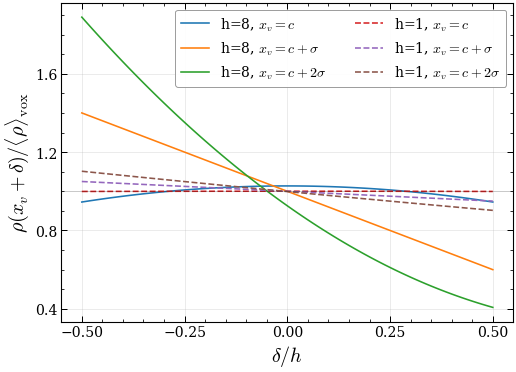

In [ ]:
# WM3 (closed-form): intra-voxel density at three representative voxels and the
# cell-average vs centroid potential shift Delta(x_v) = (h^2 k / 24)(3 - k|x_v-c|^2).
# LEFT panel: VOXEL-MEAN normalization rho(x_v+delta)/<rho>_vox. Curves do NOT
# pass through 1 at delta=0 in general -- the lift/dip at delta=0 IS the WM
# offset diagnostic, identical to what RIGHT panel shows via Delta(x_v).
# Saves figures/wm3_intravoxel_offset.{pdf,png}.
from pathlib import Path
from matplotlib.ticker import MaxNLocator
import subprocess
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

# Probe for LaTeX once -- fall back to mathtext if absent.
try:
    subprocess.run(['latex', '--version'], capture_output=True, check=True, timeout=5)
    USE_LATEX = True
except Exception:
    USE_LATEX = False
    print('[WM3] LaTeX binary not found; using matplotlib mathtext fallback.')

rc_pub = {
    'font.family':         'serif',
    'font.size':           14,
    'axes.labelsize':      16,
    'axes.titlesize':      15,
    'xtick.labelsize':     14,
    'ytick.labelsize':     14,
    'legend.fontsize':     14,
    'lines.linewidth':     1.6,
    'lines.markersize':    7,
    'axes.linewidth':      1.1,
    'xtick.direction':     'in',  'ytick.direction':     'in',
    'xtick.top':           True,  'ytick.right':         True,
    'xtick.minor.visible': True,  'ytick.minor.visible': True,
    'xtick.major.size':    6.0,   'ytick.major.size':    6.0,
    'xtick.minor.size':    3.0,   'ytick.minor.size':    3.0,
    'xtick.major.width':   1.0,   'ytick.major.width':   1.0,
    'xtick.minor.width':   0.8,   'ytick.minor.width':   0.8,
    'savefig.bbox':        'tight',
    'savefig.pad_inches':  0.05,
}
if USE_LATEX:
    rc_pub.update({'text.usetex': True, 'font.serif': ['Computer Modern Roman']})
else:
    rc_pub.update({'mathtext.fontset': 'cm'})

with plt.rc_context(rc_pub):
    fig, a1 = plt.subplots(figsize=(7.5,5.5))

    # (A) intra-voxel rho(x_v+delta)/rho(x_v)  (1-D harmonic Taylor, centroid-normalized)
    for h_demo, ls in ((8.0, '-'), (1.0, '--')):
        dd = np.linspace(-0.5, 0.5, 81) * h_demo            # delta in box units
        for xv, lab in [(0.0, r'$x_v=c$'), (SIGMA, r'$x_v=c+\sigma$'), (2*SIGMA, r'$x_v=c+2\sigma$')]:
            phip  = K * xv                                   # phi'(x_v)
            phipp = K                                        # phi''
            # Pointwise Taylor (numerator) and closed-form voxel-mean (denominator).
            rho_num   = 1 - phip*dd - 0.5*phipp*dd**2 + 0.5*(phip*dd)**2
            rho_denom = 1 - (h_demo**2 * K / 24.0) * (1.0 - K * xv**2)   # <rho_t>_vox, see eq:avg1d
            rho_ratio = rho_num / rho_denom                               # rho_t(delta)/<rho_t>_vox
            a1.plot(dd/h_demo, rho_ratio, ls=ls, label=f'h={h_demo:g}, {lab}')
    a1.axhline(1.0, color='k', alpha=0.3, lw=0.7)
    a1.set_xlabel(r'$\delta / h$', fontsize=20); a1.set_ylabel(r'$\rho(x_v+\delta)/\langle\rho\rangle_{\rm vox}$', fontsize=20)
    #a1.set_title('Intra-voxel density shape (1-D Taylor, harmonic)')
    a1.set_xticks([-0.5, -0.25, 0.0, 0.25, 0.5])
    a1.yaxis.set_major_locator(MaxNLocator(nbins=5))
    a1.legend(fontsize=14, ncol=2, frameon=True, framealpha=0.95, edgecolor='0.6')
    a1.grid(True, alpha=0.3)

    # (B) Delta(x_v) = (h^2 k / 24)(3 - k|x_v-c|^2), 1-D slice through center
    # xv_grid = np.linspace(-3*SIGMA, 3*SIGMA, 400)
    # for h in hs_wm:
    #     a2.plot(xv_grid, (h**2 * K / 24.0) * (3.0 - K*xv_grid**2), label=f'h = {h:g}')
    # xstar = np.sqrt(3.0 / K)                                  # sign-change locus
    # a2.axvline( xstar, color='k', alpha=0.3, ls='--'); a2.axvline(-xstar, color='k', alpha=0.3, ls='--')
    # a2.axhline(0, color='k', alpha=0.3, lw=0.7)
    # a2.text(xstar*1.03, a2.get_ylim()[1]*0.55, fr'$|x-c|=\sqrt{{3/k}}\approx{xstar:.1f}$', fontsize=8)
    # a2.set_xlabel('x - c (box units)'); a2.set_ylabel(r'$\Delta(x_v)=\phi_{\rm avg}-\phi_v$')
    # a2.set_title(r'Cell-average vs centroid potential shift  $(h^2 k/24)(3-k|x-c|^2)$  $\leftarrow$ WM error lives here')
    # a2.legend(fontsize=8); a2.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(FIG_DIR / 'wm3_intravoxel_offset.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / 'wm3_intravoxel_offset.png', bbox_inches='tight', dpi=300)
    print('  -> figures/wm3_intravoxel_offset.{pdf,png}')
    plt.show()

In [ ]:
# Replicate loader: open the 3 HDF5 files written above and build per-frame
# x/y/z 1-D marginals at each N. ALSO retain HDF5 paths for lazy 3-D access
# by WM4 (coarse-voxel-local sampling) -- the 3-D arrays stay on disk and are
# streamed one frame at a time.
#
# Output structure:
#   repA[N]['marg']     = ndarray (n_rep, n_axis, n_frame, N) float64
#                         n_axis=3 (x, y, z; statistically equivalent by isotropy)
#   repA[N]['n_part']   = ndarray (n_rep,)
#   repA[N]['times']    = ndarray (n_rep, n_frame) float64
#   repA[N]['h5_paths'] = list[str]   <-- NEW: paths to per-rep HDF5 files
# Falls back to the single-run resA if no replicates have been written.
import h5py
from pathlib import Path

REPL_DIR = Path('replicates')
rep_paths = sorted(REPL_DIR.glob('static_seed*.h5'))
print(f'Found {len(rep_paths)} replicate file(s):')
for p in rep_paths:
    print(f'  {p.name}   {p.stat().st_size / 2**20:.1f} MB')

repA = {}
if rep_paths:
    # peek the first file to learn N_SWEEP that was saved
    with h5py.File(rep_paths[0], 'r') as f0:
        sweep_saved = [int(k[1:]) for k in f0.keys() if k.startswith('N')]
    for N in sorted(sweep_saved):
        margs, nparts, tlist = [], [], []
        for p in rep_paths:
            with h5py.File(p, 'r') as f:
                g = f[f'N{N}']
                frames = g['frames']                  # (n_frame, N, N, N) uint8 on disk
                nparts.append(int(g.attrs['n_part']))
                tlist.append(g['times'][...])
                # per-axis marginals: sum over the other two axes -> (n_frame, N)
                fr = frames[...]                       # full 3-D pull (uint8)
                marg_x = fr.sum(axis=(2, 3)).astype(np.float64)   # collapse y,z
                marg_y = fr.sum(axis=(1, 3)).astype(np.float64)   # collapse x,z
                marg_z = fr.sum(axis=(1, 2)).astype(np.float64)   # collapse x,y
                margs.append(np.stack([marg_x, marg_y, marg_z], axis=0))   # (3, n_frame, N)
        repA[N] = dict(
            marg     = np.stack(margs, axis=0),       # (n_rep, 3, n_frame, N)
            n_part   = np.asarray(nparts, dtype=np.int64),
            times    = np.stack(tlist, axis=0),       # (n_rep, n_frame)
            h5_paths = [str(p) for p in rep_paths],   # for lazy 3-D access in WM4
        )
        print(f'  N={N:5d}  marg shape = {repA[N]["marg"].shape}  '
              f'n_part = {repA[N]["n_part"].tolist()}  '
              f'3D-lazy ready ({len(rep_paths)} files)')
else:
    print('  (no replicate files yet -- run the replicate-runner cell above first)')
    print('  WM4 below will fall back to the single-run resA (n=2 per shell).')


Found 0 replicate file(s):
  (no replicate files yet -- run the replicate-runner cell above first)
  WM4 below will fall back to the single-run resA (n=2 per shell).


[WM4] LaTeX binary not found; using matplotlib mathtext fallback.
source: 1-D marginal: single time-averaged run (1 sample, 2 parity voxels)
Poisson SEM uses n_part_per_sample = 300000

  h_c  | |x_v-c| | n_samp  | mean@delta=h_fine/2 | SEM    | mean@delta=+h_c/2 | SEM
-------+---------+---------+---------------------+--------+-------------------+-------
   8.0 |   4.00  |       2 |     1.00861      | 9.4e-03 |     0.82065     | 8.5e-03
   8.0 |  12.00  |       2 |     0.96084      | 1.2e-02 |     0.59099     | 9.8e-03
   8.0 |  20.00  |       2 |     0.87816      | 2.2e-02 |     0.40159     | 1.5e-02
  -> wm4_intravoxel_shape_h8.pdf, wm4_intravoxel_shape_h8.png


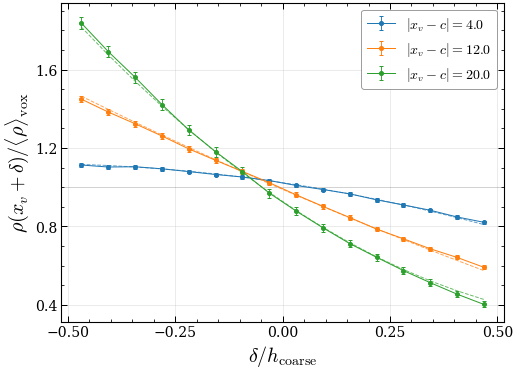

   4.0 |   2.00  |       2 |     0.99915      | 8.7e-03 |     0.95685     | 8.5e-03
   4.0 |  10.00  |       2 |     0.97060      | 1.1e-02 |     0.83070     | 1.0e-02
   4.0 |  22.00  |       2 |     0.93589      | 2.7e-02 |     0.67217     | 2.3e-02
  -> wm4_intravoxel_shape_h4.pdf, wm4_intravoxel_shape_h4.png


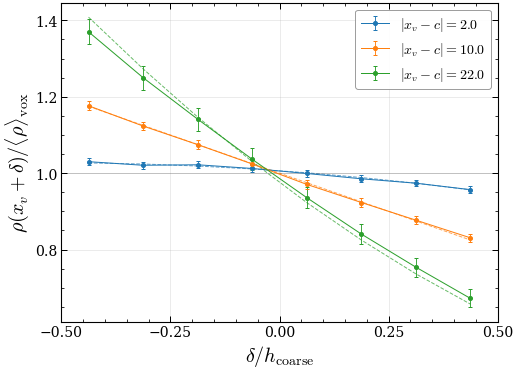

In [ ]:
# WM4: empirical intra-voxel SHAPE with replicate + axis + frame averaging.
# VOXEL-MEAN NORMALIZATION: rho(x_v + delta) / <rho>_vox. Curves do NOT
# pass through 1 at delta = 0 in general -- the lift/dip there IS the WPE
# quadrature-error diagnostic, identical to what WM3-right shows directly
# via Delta(x_v) = (h^2 k / 24)(1 - k(x_v - c)^2).
#
# Two sampling modes, selected automatically based on data availability:
#
#   * 3-D mode (when repA[N_fine]['h5_paths'] exists):
#       For each (rep, frame, cardinal axis, parity sign), pull the
#       coarse-voxel slab from the HDF5 lazily. Within that slab, sum the
#       fine-grid bins WITHIN each perpendicular coarse voxel to build
#       N_c^2 coarse-voxel-local 1-D profiles. By isotropic separability
#       of the harmonic Gaussian, each such profile has the same expected
#       ratio shape, just independent shot noise.
#       n_sample per shell ~ n_rep * 6 cardinal * N_c^2 * n_frame
#         h_c=8, N_c=32 -> ~6144 per (rep,frame) -> ~552k per shell
#         h_c=4, N_c=64 -> ~24576 per (rep,frame) -> ~2.2M per shell
#       (empty-centroid voxels are masked out; effective n is smaller.)
#
#   * 1-D marginal mode (fallback when no h5_paths):
#       Use the 1-D x/y/z marginals from repA (or single-run resA).
#       n_sample per shell = n_rep * 3 axes * n_frame * 2 parity = up to 540.
#
# Error bars are THEORETICAL Poisson shot-noise SEM (not empirical
# std/sqrt(n_sample)). Per-sample Var(R[k]) for R = p[k]/<p>_vox via
# delta method on a multinomial ratio with shared-bin correlation:
#     Var(R[k])/R^2 = 1/(n_part*a[k]) - 1/(n_fc*n_part*<a>_vox)
# Same formula for all k inside the voxel -- the voxel-mean denominator
# weights all n_fc bins equally, unlike the centroid (which used only
# two). SEM = sqrt(Var/n_sample).
#
# This panel isolates the intra-voxel SHAPE (drift tilt + diffusive
# curvature) and validates that the WPE lattice produces the correct
# Boltzmann profile inside each coarse voxel. The WPE quadrature error
# (lift/dip) is no longer encoded here -- see WM3 right and WM5.
#
# Split into two separate figures, one per coarse spacing h_c. Same
# publication formatting as WM3.
# Saves figures/wm4_intravoxel_shape_h{8,4}.{pdf,png}.
from pathlib import Path
from matplotlib.ticker import MaxNLocator
import subprocess, h5py

FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

# Probe for LaTeX once -- fall back to mathtext if absent.
try:
    subprocess.run(['latex', '--version'], capture_output=True, check=True, timeout=5)
    USE_LATEX = True
except Exception:
    USE_LATEX = False
    print('[WM4] LaTeX binary not found; using matplotlib mathtext fallback.')

rc_pub = {
    'font.family':         'serif',
    'font.size':           14,
    'axes.labelsize':      16,
    'axes.titlesize':      15,
    'xtick.labelsize':     14,
    'ytick.labelsize':     14,
    'legend.fontsize':     14,
    'lines.linewidth':     1.6,
    'lines.markersize':    7,
    'axes.linewidth':      1.1,
    'xtick.direction':     'in',  'ytick.direction':     'in',
    'xtick.top':           True,  'ytick.right':         True,
    'xtick.minor.visible': True,  'ytick.minor.visible': True,
    'xtick.major.size':    6.0,   'ytick.major.size':    6.0,
    'xtick.minor.size':    3.0,   'ytick.minor.size':    3.0,
    'xtick.major.width':   1.0,   'ytick.major.width':   1.0,
    'xtick.minor.width':   0.8,   'ytick.minor.width':   0.8,
    'savefig.bbox':        'tight',
    'savefig.pad_inches':  0.05,
}
if USE_LATEX:
    rc_pub.update({'text.usetex': True, 'font.serif': ['Computer Modern Roman']})
else:
    rc_pub.update({'mathtext.fontset': 'cm'})

N_fine = max(Ns); h_fine = L / N_fine

USE_3D = ('repA' in globals() and repA and N_fine in repA
          and 'h5_paths' in repA[N_fine] and repA[N_fine]['h5_paths'])

if USE_3D:
    h5_paths = repA[N_fine]['h5_paths']
    n_part_arr = repA[N_fine]['n_part']
    src_label = (f'3-D coarse-voxel-local: {len(h5_paths)} reps x N_c^2 perp positions '
                 f'x 6 cardinal x {repA[N_fine]["marg"].shape[2]} frames')
elif 'repA' in globals() and repA and N_fine in repA:
    M = repA[N_fine]['marg']
    n_part = repA[N_fine]['n_part'][:, None, None]
    P_ens = (M / n_part[..., None]).reshape(-1, N_fine)
    src_label = (f'1-D marginal: {M.shape[0]} reps x {M.shape[1]} axes x {M.shape[2]} frames '
                 f'= {P_ens.shape[0]} samples (each split into 2 parity voxels)')
else:
    P_ens = (resA[N_fine]['marg'] / resA[N_fine]['marg'].sum())[None, :]
    src_label = '1-D marginal: single time-averaged run (1 sample, 2 parity voxels)'
print('source:', src_label)


def shell_voxels(h_c, R, eps=1e-6):
    """Coarse voxels at signed offset +/-R from c (straddling pair when R=0)."""
    N_c = int(round(L / h_c))
    targets = [+eps, -eps] if R == 0 else [+R, -R]
    seen, out = set(), []
    for t in targets:
        j = int(np.floor((t + L/2) / h_c)); j = min(max(j, 0), N_c - 1)
        if j in seen: continue
        seen.add(j)
        x_v = (j + 0.5 - N_c/2.0) * h_c
        out.append((j, x_v))
    return out


def _poisson_sem(h_c, R, a_fine, n_part_per_sample, n_sample, eps=1e-6):
    """Theoretical per-bin SEM of the VOXEL-MEAN-normalized ratio
    R[k] = p[k] / <p>_vox  under multinomial / Poisson shot noise.

    Delta method on a ratio of correlated multinomials yields:
      Var(R[k]) / R[k]^2  =  1/(n_part * a[k])  -  1/(n_fc * n_part * <a>_vox)

    Same formula for all k inside the voxel (no special mid-1, mid case).
    Returns (n_fc,) array of SEM values."""
    n_fc = int(round(h_c / h_fine))
    N_c  = int(round(L / h_c))
    targets = [+eps] if R == 0 else [+R]
    j_c     = int(np.floor((targets[0] + L/2) / h_c)); j_c = min(max(j_c, 0), N_c - 1)
    x_v     = (j_c + 0.5 - N_c/2.0) * h_c
    i0, i1  = j_c * n_fc, j_c * n_fc + n_fc
    a_voxel = a_fine[i0:i1].astype(np.float64)
    if x_v < 0:
        a_voxel = a_voxel[::-1]
    a_mean  = a_voxel.mean()
    if a_mean <= 0:
        return np.zeros(n_fc)
    R_true  = a_voxel / a_mean
    inv_nA  = 1.0 / (n_part_per_sample * np.where(a_voxel > 0, a_voxel, 1e-30))
    inv_nM  = 1.0 / (n_fc * n_part_per_sample * a_mean)
    var_one = np.zeros(n_fc)
    for k in range(n_fc):
        if a_voxel[k] <= 0:
            var_one[k] = np.inf
            continue
        term = inv_nA[k] - inv_nM
        var_one[k] = R_true[k]**2 * max(term, 0.0)
    n_eff = max(int(n_sample), 1)
    return np.sqrt(var_one / n_eff)



def _extract_3d_shells(h_c, R_list, eps=1e-6):
    """Stream each replicate's HDF5 frames once and harvest coarse-voxel-local
    profiles for every (R, cardinal direction, parity voxel, perpendicular
    coarse position). Returns dict {R: (n_total, n_fc) profiles array} of
    centroid-normalized intra-voxel profiles, oriented outward (+delta).
    """
    n_fc = int(round(h_c / h_fine))
    N_c  = int(round(L / h_c))
    # Per-R list of unique (axis, j_c, x_v) shell voxels.
    per_R_voxels = {}
    for R in R_list:
        tgts = [+eps, -eps] if R == 0 else [+R, -R]
        triples = []
        for axis_idx in range(3):
            seen = set()
            for t in tgts:
                j = int(np.floor((t + L/2) / h_c)); j = min(max(j, 0), N_c - 1)
                if j in seen: continue
                seen.add(j)
                x_v = (j + 0.5 - N_c/2.0) * h_c
                triples.append((axis_idx, j, x_v))
        per_R_voxels[R] = triples

    bucket = {R: [] for R in R_list}
    for h5_path in h5_paths:
        with h5py.File(h5_path, 'r') as f:
            ds = f[f'N{N_fine}/frames']               # (n_frame, N, N, N) uint8
            n_frame = ds.shape[0]
            for fi in range(n_frame):
                vol = ds[fi]                          # (N, N, N) uint8
                for R in R_list:
                    for axis_idx, j_c, x_v in per_R_voxels[R]:
                        i0 = j_c * n_fc; i1 = i0 + n_fc
                        if axis_idx == 0:
                            slab = vol[i0:i1, :, :]                       # (n_fc, N, N)
                        elif axis_idx == 1:
                            slab = vol[:, i0:i1, :].transpose(1, 0, 2)    # (n_fc, N, N)
                        else:
                            slab = vol[:, :, i0:i1].transpose(2, 0, 1)    # (n_fc, N, N)
                        # Sum fine perpendicular bins within each perpendicular coarse voxel.
                        s5 = slab.reshape(n_fc, N_c, n_fc, N_c, n_fc)
                        coarse_perp = s5.sum(axis=(2, 4))                 # (n_fc, N_c, N_c)
                        # Each (perp_a, perp_b) coarse cell -> one length-n_fc profile.
                        profs = coarse_perp.transpose(1, 2, 0).reshape(-1, n_fc).astype(np.float64)
                        if x_v < 0:
                            profs = profs[:, ::-1]                        # mirror outward
                        # Voxel-mean denominator (matches closed-form <rho>_vox).
                        p_vmean = profs.mean(axis=1)
                        ok = p_vmean > 0                                  # drop empty voxels
                        if not np.any(ok):
                            continue
                        bucket[R].append(profs[ok] / p_vmean[ok, None])
    return {R: (np.concatenate(rows, axis=0) if rows else np.zeros((0, n_fc)))
            for R, rows in bucket.items()}


def _extract_1d_shells(h_c, R_list):
    """1-D marginal fallback: stack parity voxels as separate samples."""
    n_fc = int(round(h_c / h_fine))
    out = {}
    for R in R_list:
        voxels = shell_voxels(h_c, R)
        rows = []
        for j, x_v in voxels:
            i0 = j * n_fc; i1 = i0 + n_fc
            p_slice = P_ens[:, i0:i1]
            if x_v < 0:
                p_slice = p_slice[:, ::-1]
            # Voxel-mean denominator (matches closed-form <rho>_vox).
            p_vmean = p_slice.mean(axis=1, keepdims=True)
            p_vmean = np.where(p_vmean > 0, p_vmean, 1.0)
            rows.append(p_slice / p_vmean)
        out[R] = np.concatenate(rows, axis=0) if rows else np.zeros((0, n_fc))
    return out


R_LIST = (0.0, SIGMA, 2*SIGMA)
COLORS = ('C0', 'C1', 'C2')

# Theoretical Poisson bars need (i) the analytic 1-D Gaussian at fine bins,
# and (ii) the effective per-sample particle count.
_a_fine_wm4 = analytic_marginal(N_fine)
if 'repA' in globals() and repA and N_fine in repA:
    _n_part_per_sample = float(np.mean(repA[N_fine]['n_part']))
else:
    _n_part_per_sample = float(resA[N_fine]['n_part'])
print(f'Poisson SEM uses n_part_per_sample = {_n_part_per_sample:.0f}')

print()
print('  h_c  | |x_v-c| | n_samp  | mean@delta=h_fine/2 | SEM    | mean@delta=+h_c/2 | SEM')
print('-------+---------+---------+---------------------+--------+-------------------+-------')
with plt.rc_context(rc_pub):
    for h_c in (8.0, 4.0):
        n_fc = int(round(h_c / h_fine))
        if n_fc < 2 or n_fc % 2 != 0:
            raise ValueError(f'n_fc={n_fc} must be even and >=2 for centroid interpolation')
        d_out = ((np.arange(n_fc) + 0.5) / n_fc - 0.5) * h_c

        # One pass through the data per h_c to grab all R shells.
        shells = _extract_3d_shells(h_c, R_LIST) if USE_3D else _extract_1d_shells(h_c, R_LIST)

        fig, ax = plt.subplots(figsize=(7.5, 5.5))
        for R, color in zip(R_LIST, COLORS):
            per_sample = shells[R]
            x_v_mag = abs(shell_voxels(h_c, R)[0][1])
            if per_sample.shape[0] == 0:
                print(f'  WARNING: no samples in shell |x_v-c|={x_v_mag:.1f}')
                continue
            mean = per_sample.mean(axis=0)
            # Theoretical Poisson shot-noise SEM (replaces empirical std/sqrt(n)).
            # Per-sample n_part = total particles in one (rep, axis, frame) marginal.
            sem  = _poisson_sem(h_c, R, _a_fine_wm4, _n_part_per_sample,
                                per_sample.shape[0])
            ax.errorbar(d_out / h_c, mean, yerr=sem, fmt='o-', ms=4, lw=1.0,
                        color=color, capsize=2, ecolor=color, elinewidth=0.9,
                        label=fr'$|x_v-c|={x_v_mag:.1f}$')
            # Taylor voxel-mean-normalized: rho_t / <rho_t>_vox
            # (midpoint Riemann over the n_fc fine bins; matches the empirical
            # voxel mean above byte-for-byte).
            phip = K * x_v_mag; phipp = K
            rho_t = 1 - phip*d_out - 0.5*phipp*d_out**2 + 0.5*(phip*d_out)**2
            ax.plot(d_out / h_c, rho_t / rho_t.mean(), '--', lw=1.0, alpha=0.7, color=color)
            kmid  = n_fc // 2
            kedge = n_fc - 1
            print(f'  {h_c:4.1f} | {x_v_mag:6.2f}  | {per_sample.shape[0]:7d} '
                  f'|     {mean[kmid]:.5f}      | {sem[kmid]:.1e} '
                  f'|     {mean[kedge]:.5f}     | {sem[kedge]:.1e}')
        ax.axhline(1.0, color='k', alpha=0.25, lw=0.7)
        ax.set_xlabel(r'$\delta / h_{\rm coarse}$', fontsize=20)
        ax.set_ylabel(r'$\rho(x_v+\delta) / \langle\rho\rangle_{\rm vox}$', fontsize=20)
        ax.set_xticks([-0.5, -0.25, 0.0, 0.25, 0.5])
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.legend(fontsize=14, frameon=True, framealpha=0.95, edgecolor='0.6')
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        out_pdf = FIG_DIR / f'wm4_intravoxel_shape_h{h_c:g}.pdf'
        out_png = FIG_DIR / f'wm4_intravoxel_shape_h{h_c:g}.png'
        fig.savefig(out_pdf, bbox_inches='tight')
        fig.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f'  -> {out_pdf.name}, {out_png.name}')
        plt.show()


  N |  h    |  measured rel-3D  |  WM-predicted rel-3D  |  ratio
----+-------+-------------------+-----------------------+--------
  32| 8.000 |     4.936e-01     |       1.200e-01        |  4.11
  64| 4.000 |     2.536e-01     |       3.000e-02        |  8.45
 128| 2.000 |     1.314e-01     |       7.500e-03        |  17.52
 256| 1.000 |     6.999e-02     |       1.875e-03        |  37.33
 512| 0.500 |     3.305e-02     |       4.687e-04        |  70.51
  -> figures/wm5_rel3dL2.{pdf,png}


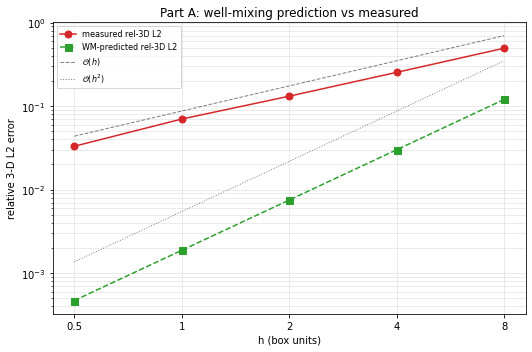

In [14]:
# WM5: closed-form well-mixing prediction of the relative 3-D L2 error, overlaid
# on the measured curve. Per voxel: delta p / p = (h^2/24)(3k - k^2 |x_v-c|^2). Under
# separability & isotropy: rel-3D L2 ~ sqrt(3) * sqrt(sum a^2 (dp/p)^2) / sqrt(sum a^2).
from matplotlib.ticker import FuncFormatter, NullFormatter

hs_pred = np.array([L/N for N in N_SWEEP], dtype=float)
rel3_pred = np.zeros(len(N_SWEEP))
rel3_meas = np.zeros(len(N_SWEEP))
for i, N in enumerate(N_SWEEP):
    h = L / N
    a = analytic_marginal(N)
    xv = (np.arange(N) + 0.5 - N/2.0) * h
    dpop = (h**2 / 24.0) * (3.0*K - K**2 * xv**2)
    num = np.sqrt(np.sum(a**2 * dpop**2)); den = np.sqrt(np.sum(a**2))
    rel3_pred[i] = np.sqrt(3.0) * num / den
    p = resA[N]['marg'] / resA[N]['marg'].sum()
    spp, saa, spa = (p*p).sum(), (a*a).sum(), (p*a).sum()
    rel3_meas[i] = np.sqrt(max(spp**3 - 2*spa**3 + saa**3, 0.0)) / np.sqrt(saa**3)

print('  N |  h    |  measured rel-3D  |  WM-predicted rel-3D  |  ratio')
print('----+-------+-------------------+-----------------------+--------')
for N, h, m, q in zip(N_SWEEP, hs_pred, rel3_meas, rel3_pred):
    r = (m/q) if q > 0 else float('nan')
    print(f'{N:4d}| {h:.3f} |     {m:.3e}     |       {q:.3e}        |  {r:.2f}')

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(hs_pred, rel3_meas, 'o-', ms=7, color='C3', label='measured rel-3D L2')
ax.plot(hs_pred, rel3_pred, 's--', ms=7, color='C2', label='WM-predicted rel-3D L2')
ia = int(np.argmax(hs_pred)); h0, y0 = hs_pred[ia], rel3_meas[ia]
hl = np.array([hs_pred.min(), hs_pred.max()]); f = np.sqrt(2.0)
ax.plot(hl, (y0*f)*(hl/h0)**1, 'k--', lw=1.0, alpha=0.5, label=r'$\mathcal{O}(h)$')
ax.plot(hl, (y0/f)*(hl/h0)**2, 'k:',  lw=1.0, alpha=0.5, label=r'$\mathcal{O}(h^2)$')
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(hs_pred); ax.xaxis.set_major_formatter(FuncFormatter(lambda v,_: f'{v:g}'))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel('h (box units)'); ax.set_ylabel('relative 3-D L2 error')
ax.set_title('Part A: well-mixing prediction vs measured')
ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
from pathlib import Path
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / 'wm5_rel3dL2.pdf', bbox_inches='tight')
fig.savefig(FIG_DIR / 'wm5_rel3dL2.png', bbox_inches='tight', dpi=300)
print('  -> figures/wm5_rel3dL2.{pdf,png}')
plt.show()

## Test 2: Moving well ($\omega>0$)

At a single resolution we drive the well center along the cube diagonal, $x_0(t)=\text{center}+c\sin\omega t$
on every axis, by recomputing $\phi(\mathbf x,t)$ each step in a `hookSimulation` callback and uploading
it with `setBasisField`. The cloud center should follow
$\mu(t)-\text{center}=A\sin(\omega t-\delta)$ with $A=\tfrac{Dk}{\sqrt{(Dk)^2+\omega^2}}\,c$ and
$\delta=\arctan(\omega/Dk)$, while the width stays $\sigma=1/\sqrt{k}$. We use $\omega=Dk$ (lag $45^\circ$,
attenuation $0.71$). No potential cap is needed: the cloud stays well inside the box, so it never
reaches the periodic seam.

In [9]:
N_B    = 128
OMEGA  = DK            # lag 45 deg, attenuation 1/sqrt(2)
C_AMP  = 40.0          # well-center oscillation amplitude (box units)
N_PER  = 3.0           # periods to simulate
atten  = DK / np.sqrt(DK**2 + OMEGA**2)
delta  = np.arctan2(OMEGA, DK)
print(f'expected: amplitude A = {atten*C_AMP:.2f} units, lag delta = {np.degrees(delta):.1f} deg, width = {SIGMA:.1f}')

h_B = L / N_B
dt_B = C_STAB * (h_B * UNIT)**2 / D
ax_b = ((np.arange(N_B) - N_B / 2.0) * h_B).astype(np.float64)   # offset from center, box units
centerv = N_B / 2.0

class MovingWell:
    def __init__(self, *a, **k):
        super().__init__()
        self.calls = 0
    def hookSimulation(self, t, lattice):
        s = C_AMP * np.sin(OMEGA * t)                            # diagonal displacement (box units)
        ox, oy, oz = ax_b - s, ax_b - s, ax_b - s
        phi = 0.5 * K * (ox[:, None, None]**2 + oy[None, :, None]**2 + oz[None, None, :]**2)
        self.setBasisField(0, np.ascontiguousarray(phi.ravel(), dtype=np.float64))
        self.calls += 1
        return 1

with tempfile.TemporaryDirectory() as wd:
    fname = os.path.join(wd, 'fpB.lm')
    sim = RDMESim(name='fpB', filename=fname, dimensions=[N_B, N_B, N_B],
                  latticeSpacing=h_B * UNIT, regionName='cyt', latticeType='Byte', dt=dt_B)
    P = sim.species('P'); sim.diffusionConst('D', D)
    sim.transitionRate(None, None, None, sim.diffusionZero)
    sim.transitionRate(P, sim.region('cyt'), sim.region('cyt'), sim.dc.D)
    sigv_B = SIGMA / h_B
    n_part_B = int(np.clip(0.25 * PPS * (2 * np.pi)**1.5 * sigv_B**3, 2000, 300_000))
    print('Part B: N=%d, n_part=%d, sigma=%.2f vox' % (N_B, n_part_B, sigv_B))
    seed_gaussian(sim, P, N_B, n_part_B, np.random.default_rng(0))   # blob at center
    sim.simulationTime = N_PER * 2 * np.pi / OMEGA
    total = int(round(sim.simulationTime / dt_B))
    sim.latticeWriteInterval = max(1, total // 120); sim.speciesWriteInterval = sim.latticeWriteInterval
    sim.hookInterval = max(1, total // (int(N_PER) * 400))          # ~400 field updates per period
    sim.finalize()
    Sol = Solvers.makeSolver(lm.DriftMpdRdmeSolver, MovingWell); solver = Sol()
    solver.setPotentialBasis(np.zeros(N_B**3, np.float32), np.zeros(N_B**3, np.float32))
    solver.setSpeciesCoupling(0, 1.0, 0.0)
    fB = sim.run(solver=solver, cudaDevices=[0])
    print('hook calls:', solver.calls)
    grp = fB.h5['Simulations/0000001/Lattice']; keys = sorted(grp.keys())
    ts = fB.h5['Simulations/0000001/LatticeTimes'][...]
    xs = np.arange(N_B); T, COM, WID = [], [], []
    for j, k in enumerate(keys):
        cnt = (grp[k][...] == P.idx).sum(axis=3)
        # average COM over the 3 axes (well moves equally on all three)
        cs, ws = [], []
        for axn in (0, 1, 2):
            per = cnt.sum(axis=tuple(a for a in (0, 1, 2) if a != axn)).astype(float)
            m = (xs * per).sum() / per.sum(); cs.append(m); ws.append(np.sqrt((per * (xs - m)**2).sum() / per.sum()))
        T.append(ts[j]); COM.append((np.mean(cs) - centerv) * h_B); WID.append(np.mean(ws) * h_B)
    T, COM, WID = map(np.array, (T, COM, WID))

expected: amplitude A = 28.28 units, lag delta = 45.0 deg, width = 10.0
Part B: N=128, n_part=7874, sigma=5.00 vox
2026-05-22 18:11:40) Info: Using 224 processor(s) and 1 CUDA device(s) per process.
2026-05-22 18:11:40) Info: Assigning 1.00 processor(s) and 1.00 CUDA device(s) per replicate.
2026-05-22 18:11:40) Info: Data output thread running.
2026-05-22 18:11:40) Info: MPDRDME: Rng seed: top word 531226710, bottom word 1
2026-05-22 18:11:40) Info: Running mpd rdme simulation with 1 species, 0 reactions, 1 site types for 1.884956e-01 s with tau 4.000000e-05. Writing species at 6.952725e-310 and lattice at 5.371318e-310 intervals
2026-05-22 18:11:40) Info: Time is 0.00012000000000
2026-05-22 18:11:40) Info: Hook time is 0.00012000000000, in steps is 3
2026-05-22 18:11:40) Info: Next hook time is 6
2026-05-22 18:11:40) Info: Time is 0.00024000000000
2026-05-22 18:11:40) Info: Hook time is 0.00024000000000, in steps is 6
2026-05-22 18:11:40) Info: Next hook time is 9
2026-05-22 18:11:40

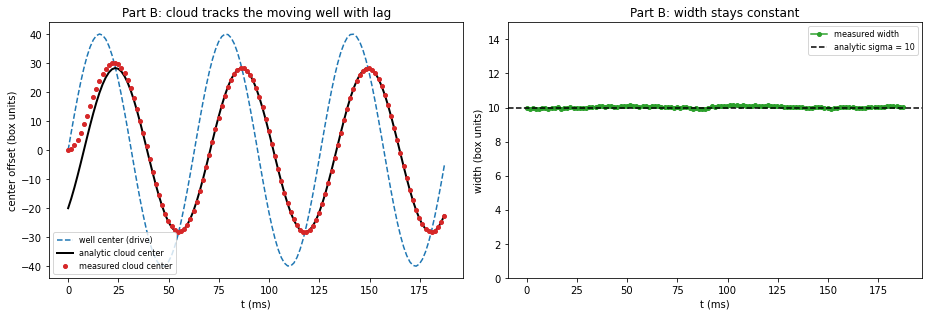

measured amplitude = 28.24  (analytic 28.28)
measured lag       = 45.4 deg (analytic 45.0 deg)
mean width         = 10.03  (analytic 10.00)


In [10]:
# Fit COM(t) = a sin(wt) + b cos(wt) over the last 2 periods -> amplitude & lag
msk = T > T.max() - 2 * 2 * np.pi / OMEGA
M = np.c_[np.sin(OMEGA * T[msk]), np.cos(OMEGA * T[msk])]
coef, *_ = np.linalg.lstsq(M, COM[msk], rcond=None)
amp = np.hypot(*coef); lag = np.degrees(np.arctan2(-coef[1], coef[0]))
lag = lag if lag >= 0 else lag + 180

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(T * 1e3, C_AMP * np.sin(OMEGA * T), 'C0--', lw=1.5, label='well center (drive)')
a1.plot(T * 1e3, atten * C_AMP * np.sin(OMEGA * T - delta), 'k-', lw=2, label='analytic cloud center')
a1.plot(T * 1e3, COM, 'C3o', ms=4, label='measured cloud center')
a1.set_xlabel('t (ms)'); a1.set_ylabel('center offset (box units)'); a1.legend(fontsize=8)
a1.set_title('Part B: cloud tracks the moving well with lag')
a2.plot(T * 1e3, WID, 'C2o-', ms=4, label='measured width')
a2.axhline(SIGMA, color='k', ls='--', label=f'analytic sigma = {SIGMA:.0f}')
a2.set_xlabel('t (ms)'); a2.set_ylabel('width (box units)'); a2.set_ylim(0, 1.5 * SIGMA); a2.legend(fontsize=8)
a2.set_title('Part B: width stays constant')
plt.tight_layout(); plt.show()

print(f'measured amplitude = {amp:.2f}  (analytic {atten*C_AMP:.2f})')
print(f'measured lag       = {lag:.1f} deg (analytic {np.degrees(delta):.1f} deg)')
print(f'mean width         = {WID.mean():.2f}  (analytic {SIGMA:.2f})')

## Figure 4: validating the temporal flatness condition

Two sweeps at fixed `h = 2`. The frequency sweep tests the analytic NESS; the timestep sweep
isolates $\varepsilon^{(1)}_\tau$ by holding the physics fixed and moving only $\tau$.
Raw fit results are cached to `figures/wm6_omega_tau_sweep.npz` so the figure can be redrawn
without re-running the simulations.


In [ ]:
# WM6 / Figure 4: the two sweeps that test the TEMPORAL flatness condition.
#
#   (a) FREQUENCY response, omega/Dk in OM_RATIOS at fixed tau. Tests the analytic NESS itself:
#       amplitude Dk/sqrt((Dk)^2+omega^2) and lag arctan(omega/Dk). It CANNOT drive
#       eps_tau^(1) to unity -- the response attenuates as 1/omega, and by the time
#       eps_tau^(1)(2 sigma) reaches 1 (near omega = 30 Dk) the amplitude is 0.67 voxels
#       and the COM fit is shot-noise dominated.
#   (b) TIMESTEP response, tau in TAU_MULT * tau0 at fixed omega = 3 Dk. Holds the amplitude
#       at 6.3 voxels while carrying eps_tau^(1)(2 sigma) from 0.17 to 0.83, and keeps
#       eps_samp = C_STAB * mult <= 1/2. This is the sweep that isolates the condition,
#       because h and the physics are both fixed and only tau moves.
#       TAU_MULT tops out at 5: mult 5 is eps_samp = 0.50 EXACTLY, the edge of the
#       sampling bound. Do not extend it.
#
# Cost: a run is a fixed number of drive periods, so wallclock scales as 1/omega.
# omega = 0.1 Dk is ~47k steps at tau0; omega = 10 Dk is ~470. The low-omega end dominates.
N_F        = 128                 # h = 2, held fixed in BOTH sweeps
OM_RATIOS  = [0.1, 0.3, 1.0, 3.0, 10.0]
TAU_MULT   = [1, 2, 4, 5]        # x tau0; 5 -> eps_samp = 0.50, the bound
OM_FIXED   = 3.0                 # omega/Dk for the timestep sweep
N_PER_S    = 3.0

h_F   = L / N_F
tau0  = C_STAB * (h_F * UNIT)**2 / D
ax_f  = ((np.arange(N_F) - N_F / 2.0) * h_F).astype(np.float64)
ctr_f = N_F / 2.0

def eps_tau1(tau, omega, r):
    """First-order temporal flatness at distance r from the well centre, worst phase,
    along the drag diagonal: sqrt(3) tau k c omega r  (SI Eq. draggedHarmonicTemporalEps)."""
    return np.sqrt(3.0) * tau * K * C_AMP * omega * r

def run_drag(omega, tau, n_per=N_PER_S, seed=0):
    """One dragged-harmonic run; returns (amplitude, lag_deg, mean_width) from the
    same lstsq fit used for the single-omega case above."""
    class Well:
        def __init__(self, *a, **k): super().__init__(); self.calls = 0
        def hookSimulation(self, t, lattice):
            s = C_AMP * np.sin(omega * t)
            o = ax_f - s
            phi = 0.5 * K * (o[:, None, None]**2 + o[None, :, None]**2 + o[None, None, :]**2)
            self.setBasisField(0, np.ascontiguousarray(phi.ravel(), dtype=np.float64))
            self.calls += 1
            return 1
    with tempfile.TemporaryDirectory() as wd:
        sim = RDMESim(name='fpS', filename=os.path.join(wd, 'fpS.lm'),
                      dimensions=[N_F, N_F, N_F], latticeSpacing=h_F * UNIT,
                      regionName='cyt', latticeType='Byte', dt=tau)
        P = sim.species('P'); sim.diffusionConst('D', D)
        sim.transitionRate(None, None, None, sim.diffusionZero)
        sim.transitionRate(P, sim.region('cyt'), sim.region('cyt'), sim.dc.D)
        sigv = SIGMA / h_F
        n_part = int(np.clip(0.25 * PPS * (2 * np.pi)**1.5 * sigv**3, 2000, 300_000))
        seed_gaussian(sim, P, N_F, n_part, np.random.default_rng(seed))
        sim.simulationTime = n_per * 2 * np.pi / omega
        total = int(round(sim.simulationTime / tau))
        sim.latticeWriteInterval = max(1, total // 120)
        sim.speciesWriteInterval = sim.latticeWriteInterval
        sim.hookInterval = max(1, total // (int(n_per) * 400))
        sim.finalize()
        Sol = Solvers.makeSolver(lm.DriftMpdRdmeSolver, Well); solver = Sol()
        solver.setPotentialBasis(np.zeros(N_F**3, np.float32), np.zeros(N_F**3, np.float32))
        solver.setSpeciesCoupling(0, 1.0, 0.0)
        f = sim.run(solver=solver, cudaDevices=[0])
        grp = f.h5['Simulations/0000001/Lattice']
        ts  = f.h5['Simulations/0000001/LatticeTimes'][...]
        xs  = np.arange(N_F); T, COM, WID = [], [], []
        for j, key in enumerate(sorted(grp.keys())):
            cnt = (grp[key][...] == P.idx).sum(axis=3)
            cs, ws = [], []
            for axn in (0, 1, 2):
                per = cnt.sum(axis=tuple(a for a in (0, 1, 2) if a != axn)).astype(float)
                m = (xs * per).sum() / per.sum(); cs.append(m)
                ws.append(np.sqrt((per * (xs - m)**2).sum() / per.sum()))
            T.append(ts[j]); COM.append((np.mean(cs) - ctr_f) * h_F); WID.append(np.mean(ws) * h_F)
    T, COM, WID = map(np.array, (T, COM, WID))
    msk = T > T.max() - 2 * 2 * np.pi / omega          # last two drive periods
    M = np.c_[np.sin(omega * T[msk]), np.cos(omega * T[msk])]
    coef, *_ = np.linalg.lstsq(M, COM[msk], rcond=None)
    amp = float(np.hypot(*coef))
    lag = float(np.degrees(np.arctan2(-coef[1], coef[0])))
    return amp, (lag if lag >= 0 else lag + 180), float(WID.mean())

rows_f, rows_t = [], []
print('--- (a) frequency response, tau = %.0f us, h = %g ---' % (tau0 * 1e6, h_F))
for r in OM_RATIOS:
    w = r * DK
    amp, lag, wid = run_drag(w, tau0)
    a_an = DK / np.hypot(DK, w) * C_AMP; d_an = np.degrees(np.arctan2(w, DK))
    rows_f.append((r, tau0, amp, a_an, lag, d_an, wid, eps_tau1(tau0, w, 2 * SIGMA)))
    print(f'  omega/Dk={r:5.2f}  A={amp:7.3f} (an {a_an:7.3f})  lag={lag:6.2f} (an {d_an:6.2f})'
          f'  eps_tau={rows_f[-1][-1]:.3f}')

print('--- (b) timestep response, omega = %g Dk, h = %g ---' % (OM_FIXED, h_F))
w = OM_FIXED * DK
for mult in TAU_MULT:
    tau = mult * tau0
    amp, lag, wid = run_drag(w, tau)
    a_an = DK / np.hypot(DK, w) * C_AMP; d_an = np.degrees(np.arctan2(w, DK))
    rows_t.append((OM_FIXED, tau, amp, a_an, lag, d_an, wid, eps_tau1(tau, w, 2 * SIGMA)))
    print(f'  tau={tau*1e6:6.1f} us  eps_samp={C_STAB*mult:.2f}  A={amp:7.3f} (an {a_an:7.3f})'
          f'  lag={lag:6.2f} (an {d_an:6.2f})  eps_tau={rows_t[-1][-1]:.3f}')

np.savez('figures/wm6_omega_tau_sweep.npz',
         freq=np.array(rows_f), tstep=np.array(rows_t),
         cols=np.array(['omega_over_Dk', 'tau_s', 'amp', 'amp_analytic',
                        'lag_deg', 'lag_deg_analytic', 'width', 'eps_tau1_2sigma']))
print('  -> figures/wm6_omega_tau_sweep.npz  (plot cell reads this; no re-running to replot)')


## Interpretation

- **Part A** confirms the WPE/Scharfetter–Gummel scheme reproduces the static Boltzmann Gaussian on a
  periodic lattice, and that the discrete distribution converges to the continuum Gaussian as $h\to0$
  (both the marginal-shape $L_2$ error and the width error shrink with $h$). The coarsest lattices
  ($N=32,64$) under-resolve the cloud ($\sigma\lesssim 2.5$ voxels) and carry the largest error.
- **Part B** confirms the time-dependent response: the cloud center tracks the moving well with the
  predicted amplitude attenuation $Dk/\sqrt{(Dk)^2+\omega^2}$ and phase lag $\arctan(\omega/Dk)$, while
  the width stays at $1/\sqrt{k}$ — exactly the Fokker–Planck solution. The field is driven from Python
  via a `hookSimulation` callback (`setBasisField` each step).

**Knobs.** `K` sets the width; `C_STAB` the timestep (kept under the diffusion CFL); seeding from the
equilibrium Gaussian keeps fine-$h$ runs cheap. For Part B, `OMEGA` relative to `DK` sets the lag and
attenuation; raise the particle count or periods to reduce shot noise in $\mu(t)$.